---
title: "Chapter 15: DBSCAN and Hierarchical Clustering"
---


::: {.callout-lo}

By the end of this chapter, you will be able to:

- Explain when K-Means may be unsuitable.
- Explain and apply DBSCAN, including its point types and density parameters.
- Explore DBSCAN settings and recognize its limitations.
- Interpret dendrograms and extract flat clusters using appropriate distances and linkage criteria.
- Choose and assess clustering methods using representation, stability, and domain knowledge.
:::

K-Means represents each cluster by a centre. This makes it fast and useful, but not every group is well described by its centre. In this chapter, we explore two alternatives. DBSCAN searches for connected regions of high density, while hierarchical clustering builds a sequence of nested groupings.

In [1]:
#| code-fold: true
#| code-summary: "Show imports and plotting helpers"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({"font.size": 12, "figure.figsize": (6, 4)})


def plot_cluster_labels(X, labels, ax=None, title=None, annotate=False):
    """Plot a partition, with noise shown as grey crosses."""
    if ax is None:
        _, ax = plt.subplots()
    labels = np.asarray(labels)
    for label in np.unique(labels):
        mask = labels == label
        colour = "grey" if label == -1 else f"C{int(label) % 10}"
        ax.scatter(
            X[mask, 0], X[mask, 1], s=70, color=colour,
            marker="x" if label == -1 else "o",
            **({"edgecolors": "black", "linewidths": 0.6} if label != -1 else {}),
            label="noise" if label == -1 else f"cluster {label}",
        )
    if annotate:
        for i, point in enumerate(X):
            ax.annotate(str(i), point, xytext=(6, 6), textcoords="offset points")
    ax.set(xlabel="Feature 0", ylabel="Feature 1", title=title)
    ax.set_aspect("equal", adjustable="box")
    return ax


def plot_dbscan(X, model, ax, title):
    """Use colour for cluster membership and marker size for point type."""
    labels = model.labels_
    core = np.zeros(len(X), dtype=bool)
    core[model.core_sample_indices_] = True
    for label in sorted(set(labels) - {-1}):
        colour = f"C{int(label) % 10}"
        for is_core, size in [(True, 55), (False, 22)]:
            mask = (labels == label) & (core == is_core)
            ax.scatter(X[mask, 0], X[mask, 1], s=size, color=colour,
                       edgecolor="black", linewidth=0.4)
    noise = labels == -1
    ax.scatter(X[noise, 0], X[noise, 1], color="grey", marker="x", s=35)
    n_clusters = len(set(labels) - {-1})
    cluster_word = "cluster" if n_clusters == 1 else "clusters"
    ax.set_title(f"{title}\n{n_clusters} {cluster_word}; {noise.mean():.0%} noise")
    ax.set(xlabel="Feature 0", ylabel="Feature 1")
    ax.set_aspect("equal", adjustable="box")


def plot_hierarchy_cut(X, Z, labels, height, title):
    """Match dendrogram branch colours to flat-cluster colours."""
    n = len(X)
    members = {i: [i] for i in range(n)}
    for i, row in enumerate(Z):
        members[n + i] = members[int(row[0])] + members[int(row[1])]

    def branch_colour(node):
        groups = np.unique(labels[members[node]])
        return f"C{int(groups[0]) % 10}" if len(groups) == 1 else "grey"

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    dendrogram(Z, ax=axes[0], link_color_func=branch_colour,
               leaf_font_size=11)
    axes[0].axhline(height, color="black", linestyle="--", label=f"cut = {height:.2f}")
    axes[0].set(xlabel="Sample index", ylabel="Merge height", title=title)
    axes[0].legend()
    plot_cluster_labels(X, labels, ax=axes[1], title="Flat clusters", annotate=True)
    plt.tight_layout()

## Why move beyond K-Means?

Recall that K-Means assigns every example to its nearest cluster centre and moves the centres to reduce the total squared distance within clusters. It is a useful starting point when groups are compact and represented well by their means. Its strengths come with some limitations:

- **Cluster geometry:** boundaries between centres are linear, so curved or elongated groups can be split apart. Groups with very different sizes or densities can also be divided or combined in unwanted ways.
- **Outliers and forced assignments:** every point joins a cluster, and extreme values can pull its centre away from the main group.
- **Choosing $K$:** we must specify the number of clusters. Elbow and silhouette plots offer evidence, but not always a clear answer.
- **Initialization:** different starting centres can lead to different solutions. Multiple initializations help, but do not remove the geometric limitations.
- **Representation and scaling:** distances depend on the features and their units. This issue also affects the methods introduced in this chapter.

Consider the following examples. We give K-Means the intended number of groups, so choosing $K$ is not the difficulty here.

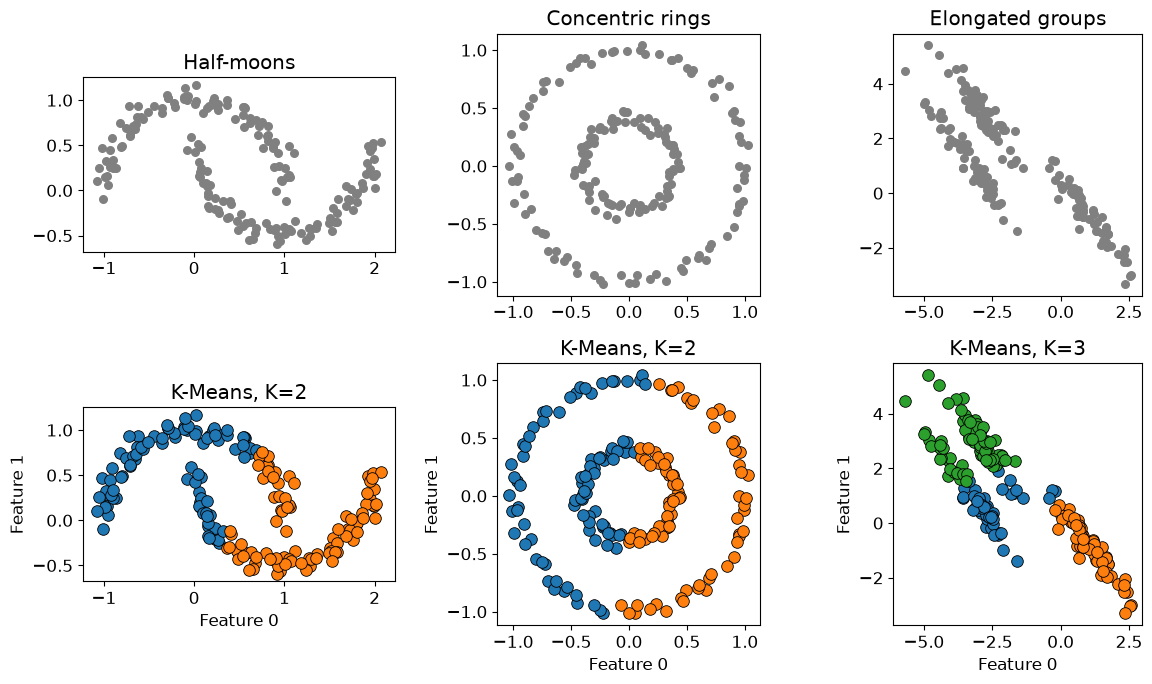

In [2]:
X_moons, _ = make_moons(n_samples=180, noise=0.07, random_state=42)
X_rings, _ = make_circles(n_samples=180, noise=0.04, factor=0.4, random_state=42)
X_elongated, _ = make_blobs(n_samples=180, centers=3, random_state=170)
X_elongated = X_elongated @ np.array([[0.6, -0.6], [-0.4, 0.8]])

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for col, (X, k, name) in enumerate([
    (X_moons, 2, "Half-moons"),
    (X_rings, 2, "Concentric rings"),
    (X_elongated, 3, "Elongated groups"),
]):
    axes[0, col].scatter(X[:, 0], X[:, 1], s=30, color="grey")
    axes[0, col].set_title(name)
    axes[0, col].set_aspect("equal", adjustable="box")
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    plot_cluster_labels(X, labels, ax=axes[1, col], title=f"K-Means, K={k}")
plt.tight_layout()

The nearest-centre rule cuts across the moons and rings, and can split elongated groups. More initializations cannot make that rule follow a curved shape. What if a cluster instead meant a region of nearby points, connected through crowded neighbourhoods?

## DBSCAN: clustering by density

**DBSCAN** stands for density-based spatial clustering of applications with noise. Its central idea is that a cluster is a connected region containing many nearby examples. Sparse examples can be left unassigned as noise.

On the half-moons data, DBSCAN can follow the curved shapes rather than dividing the plane according to the nearest centre.


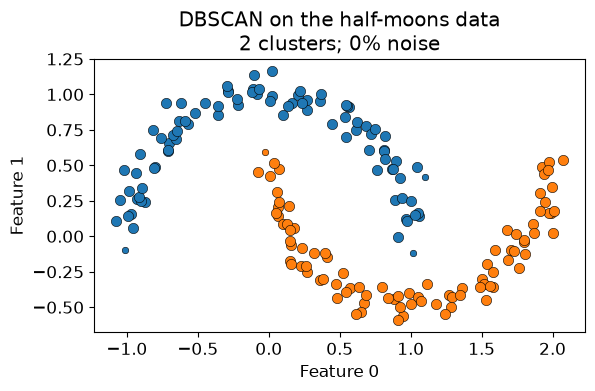

In [3]:
dbscan = DBSCAN(eps=0.22, min_samples=6).fit(X_moons)
fig, ax = plt.subplots()
plot_dbscan(X_moons, dbscan, ax, "DBSCAN on the half-moons data")
plt.tight_layout()

We did not tell DBSCAN to find two clusters. The number of clusters emerged from two other choices:

- `eps` specifies the radius of a point's neighbourhood.
- `min_samples` specifies how many examples, **including the point itself**, must fall in that neighbourhood for the point to be considered a core point.

These parameters express what “locally dense” means. Their numerical values depend on the scale and representation of the features.


::: {.callout-note title="Working with DBSCAN labels"}
`fit_predict(X)` returns one cluster label per row; after `fit(X)`, the same labels are available as `labels_`. Label `-1` means noise. Other integers identify groups, with no order or inherent meaning.

Unlike K-Means, standard scikit-learn DBSCAN has no `predict` method for new examples. To cluster an expanded dataset, fit again; adding points can change the density relationships.
:::

### Core, border, and noise points

DBSCAN distinguishes three kinds of examples:

- A **core point** has at least `min_samples` examples in its `eps`-neighbourhood, **counting itself**.
- A **border point** is not core, but lies within `eps` of a core point.
- A **noise point** is neither core nor within `eps` of any core point.

Having too few neighbours does **not** by itself make a point noise: it might be a border point. These roles depend on the chosen parameters.

The small example below uses `eps=0.5` and `min_samples=4`. Dashed circles show the neighbourhood of a core point and a border point.

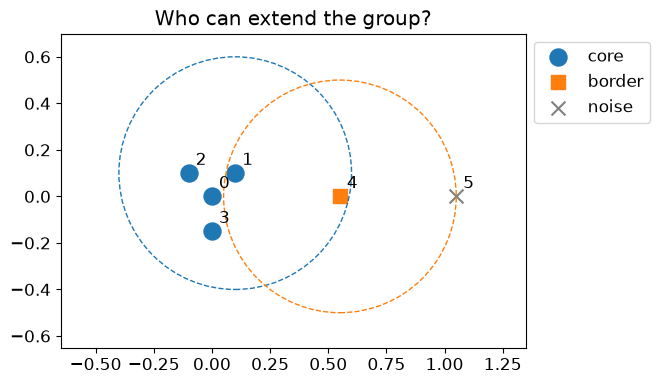

In [4]:
X_points = np.array([
    [0.0, 0.0], [0.1, 0.1], [-0.1, 0.1], [0.0, -0.15],
    [0.55, 0.0], [1.05, 0.0],
])
point_model = DBSCAN(eps=0.5, min_samples=4).fit(X_points)
point_types = np.full(len(X_points), "border", dtype=object)
point_types[point_model.labels_ == -1] = "noise"
point_types[point_model.core_sample_indices_] = "core"

fig, ax = plt.subplots(figsize=(8, 4))
for kind, marker, colour, size in [
    ("core", "o", "C0", 150), ("border", "s", "C1", 95), ("noise", "x", "grey", 100)
]:
    mask = point_types == kind
    ax.scatter(X_points[mask, 0], X_points[mask, 1], marker=marker,
               color=colour, s=size, label=kind)
for i, point in enumerate(X_points):
    ax.annotate(str(i), point, xytext=(5, 6), textcoords="offset points")
for index, colour in [(1, "C0"), (4, "C1")]:
    ax.add_patch(Circle(X_points[index], 0.5, fill=False, linestyle="--", color=colour))
ax.set(xlim=(-0.65, 1.35), ylim=(-0.65, 0.7), title="Who can extend the group?")
ax.set_aspect("equal")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()

Points 0–3 are core points. Point 4 is a border point: it is close to core point 1, but its own neighbourhood contains fewer than four points. Point 5 is close to border point 4 but outside every core point's neighbourhood, so it remains noise. **A chain of border points cannot extend a cluster.**

::: {.callout-reflection}
If we increase `eps`, could point 5 change from noise to a border point? Would changing the parameter change the data, or just our definition of a dense region?
:::

### How DBSCAN grows clusters

At a high level, DBSCAN proceeds as follows:

1. Visit an example that has not yet been processed.
2. If it is a core point, begin a new cluster and add its neighbours.
3. Whenever a newly added neighbour is also a core point, add that point's neighbours as well.
4. Continue until no more density-connected points can be reached, then visit another unprocessed example.
5. Leave examples that are not reachable from a core point labelled as noise.

The connected core points determine the clusters. Results are therefore generally deterministic for a fixed dataset and parameters. One subtle exception is a border point lying within reach of core points from two different clusters: its assignment can depend on the order in which the data are processed. The core clusters themselves do not change.


![DBSCAN expanding clusters through neighbouring core points.](img/DBSCAN_search.gif){fig-align="center" width="600"}

Watch how expansion continues through core points. Border points can receive a cluster label, but do not spread it further. A point initially left unassigned can later be reached from a core point; noise is the final status of points that never join a cluster.

Animation source: [Clustering with Scikit with GIFs](https://dashee87.github.io/data%20science/general/Clustering-with-Scikit-with-GIFs/).

### The effect of `eps` and `min_samples`

A larger `eps` makes neighbourhoods wider. More points become neighbours, so clusters may grow or merge. A larger `min_samples` makes the core-point requirement stricter; fewer points qualify as core and more may become noise.

We will reuse the noisy moons and add four isolated observations. Across all panels, **large coloured dots are core points, small coloured dots are border points, and grey crosses are noise**. Colours identify clusters within a panel; their numeric identities need not match across settings.

First, hold `min_samples` fixed and change `eps`. Predict which setting will fragment the moons and which will merge them.

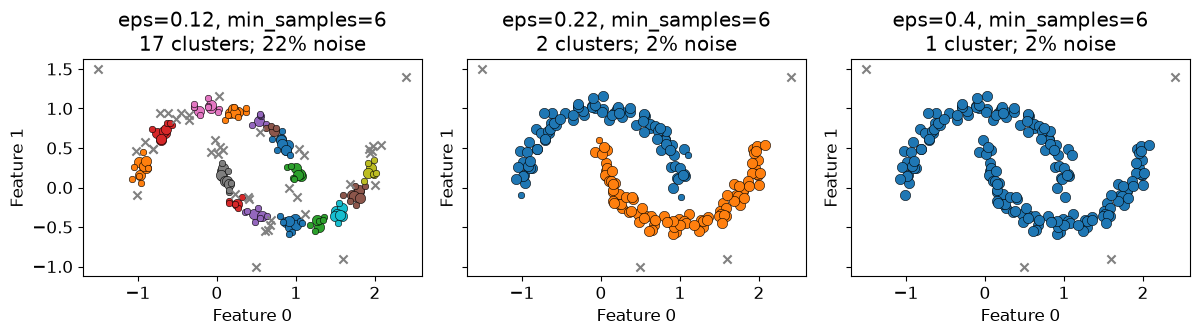

In [5]:
X_density = np.vstack([
    X_moons, [[-1.5, 1.5], [2.4, 1.4], [0.5, -1.0], [1.6, -0.9]]
])
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, eps in zip(axes, [0.12, 0.22, 0.40]):
    model = DBSCAN(eps=eps, min_samples=6).fit(X_density)
    plot_dbscan(X_density, model, ax, f"eps={eps}, min_samples=6")
plt.tight_layout()

At `eps=0.12`, neighbourhoods are too small to connect each moon. At `eps=0.22`, we recover two groups and leave the isolated points as noise. At `eps=0.40`, core points connect across the gap and the moons merge.

Now hold `eps=0.22` fixed. Increasing `min_samples` from 3 to 6 leaves the same two groups here, but increasing it to 12 breaks them into smaller pieces. Parameter changes need not change the partition immediately.

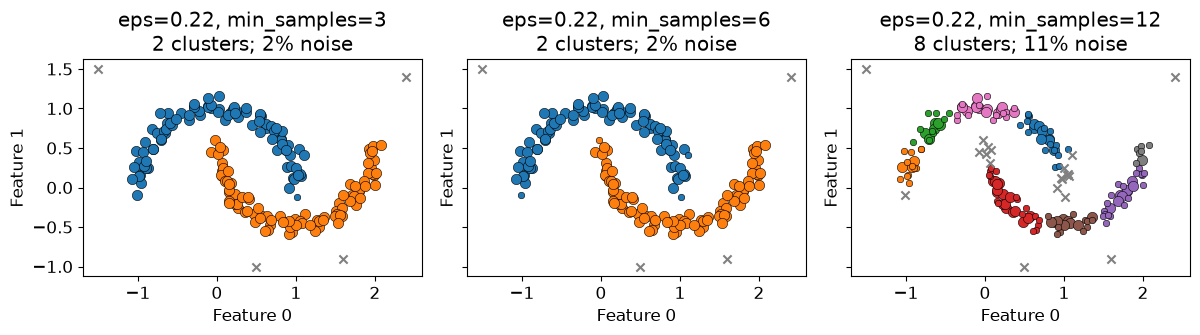

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, min_samples in zip(axes, [3, 6, 12]):
    model = DBSCAN(eps=0.22, min_samples=min_samples).fit(X_density)
    plot_dbscan(X_density, model, ax, f"eps=0.22, min_samples={min_samples}")
plt.tight_layout()

### Choosing `eps` and `min_samples` in practice

Treat tuning as a short cycle of trying settings and inspecting the resulting groups:

1. **Fix the representation and distance metric.** Distances depend on the features and their scale. For documents, choose a numerical text representation and a distance that reflects the similarity you care about; cosine distance is one option. An `eps` value that works for one representation or metric may be unsuitable for another.
2. **Try a small grid of settings.** Choose a few `min_samples` values, explore a coarse range of `eps`, then refine around promising values. The numbers below suit our toy data; do not copy them blindly to document data.
3. **Inspect the result.** Compare cluster counts, cluster sizes, and the fraction of points labelled as noise. For documents, read several examples from each cluster and ask whether they share a useful theme.

For our moons, we can collect a compact table like this:

In [7]:
rows = []
for min_samples in [3, 6, 12]:
    for eps in [0.18, 0.22, 0.26]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_density)
        rows.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": len(set(labels) - {-1}),
            "noise fraction": np.mean(labels == -1),
            "cluster sizes": pd.Series(labels[labels != -1]).value_counts().sort_index().tolist(),
        })
parameter_results = pd.DataFrame(rows)
parameter_results.round(3)

,eps,min_samples,clusters,noise fraction,cluster sizes
0,0.18,3,3,0.022,"[33, 57, 90]"
1,0.22,3,2,0.022,"[90, 90]"
2,0.26,3,1,0.022,[180]
3,0.18,6,3,0.033,"[32, 56, 90]"
4,0.22,6,2,0.022,"[90, 90]"
5,0.26,6,2,0.022,"[90, 90]"
6,0.18,12,1,0.935,[12]
7,0.22,12,8,0.109,"[24, 15, 16, 32, 26, 19, 25, 7]"
8,0.26,12,2,0.033,"[88, 90]"


The two parameters work together. At `eps=0.26`, `min_samples=3` joins the moons, while `min_samples=6` keeps them apart. Inspect the corresponding plots above rather than choosing by cluster count alone.

If **almost everything is noise**, try a larger `eps` or smaller `min_samples`. If **everything joins one large cluster**, try a smaller `eps` or larger `min_samples`. These are diagnostic directions, not guarantees: one large group or many noise points may reflect the data, and varying densities can make a useful setting hard to find.

For document clustering, prefer settings for which you can explain the main groups using representative documents, while checking exceptions and documents marked as noise. Check nearby settings too: does the interpretation persist? There is usually no target-based cross-validation score to optimize, and a high silhouette score alone does not establish that the groups are useful.

::: {.callout-reflection}
Two settings produce the same number of document clusters. One labels half the documents as noise; the other labels almost none as noise. What would you read and compare before choosing between them?
:::

### When DBSCAN struggles

DBSCAN uses one definition of density across the whole dataset. If groups have very different densities, a radius suitable for one can be unsuitable for another. The following dataset contains two tight groups and one much more spread-out group.

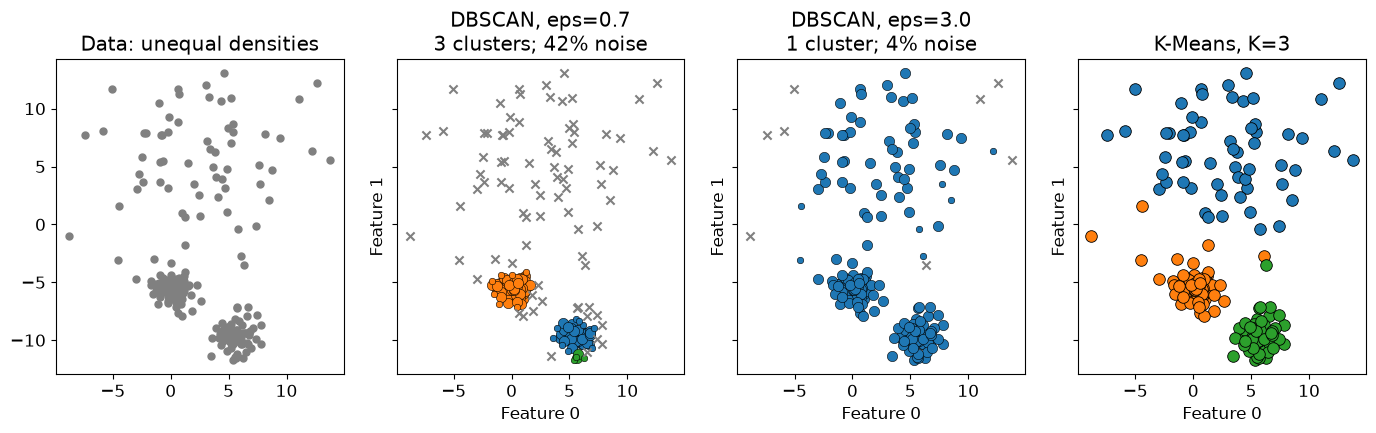

In [8]:
X_varied, _ = make_blobs(
    n_samples=200, cluster_std=[1.0, 5.0, 1.0], random_state=10
)
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharex=True, sharey=True)
axes[0].scatter(X_varied[:, 0], X_varied[:, 1], s=25, color="grey")
axes[0].set_title("Data: unequal densities")
axes[0].set_aspect("equal", adjustable="box")
for ax, eps in zip(axes[1:3], [0.7, 3.0]):
    model = DBSCAN(eps=eps, min_samples=5).fit(X_varied)
    plot_dbscan(X_varied, model, ax, f"DBSCAN, eps={eps}")
kmeans_labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_varied)
plot_cluster_labels(X_varied, kmeans_labels, ax=axes[3], title="K-Means, K=3")
plt.tight_layout()

With `eps=0.7`, DBSCAN discards much of the spread-out group. Increasing `eps` to 3.0 keeps many more points, but joins the groups into one. K-Means offers a useful alternative partition here, although it receives the extra information that we want three groups and still follows its nearest-centre rule.

Another failure can arise when a sufficiently dense bridge connects two groups. DBSCAN may then treat them as one, even if we would prefer separate groups. This requires a chain of **core** points, not just a few border points.

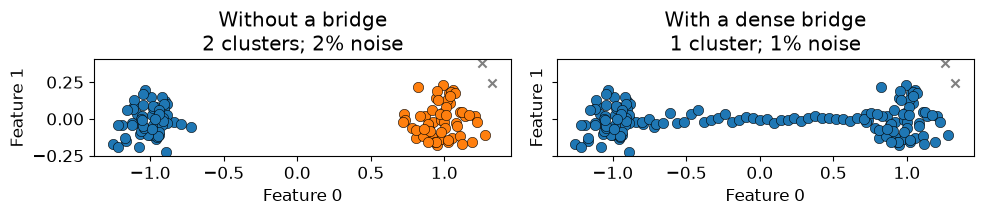

In [9]:
rng = np.random.default_rng(42)
X_groups = np.vstack([
    rng.normal(loc=(-1, 0), scale=0.13, size=(60, 2)),
    rng.normal(loc=(1, 0), scale=0.13, size=(60, 2)),
])
bridge_x = np.linspace(-0.8, 0.8, 35)
bridge = np.column_stack([bridge_x, rng.normal(0, 0.02, len(bridge_x))])
X_bridge = np.vstack([X_groups, bridge])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, X, title in zip(axes, [X_groups, X_bridge], ["Without a bridge", "With a dense bridge"]):
    model = DBSCAN(eps=0.22, min_samples=5).fit(X)
    plot_dbscan(X, model, ax, title)
plt.tight_layout()

These are limitations of what “density-connected” means, rather than problems that parameter tuning can always fix. Distances can also become less informative with many features. DBSCAN does not remove the need for careful representation and domain interpretation.

### Exercise 1: Reasoning about DBSCAN

For each change below, predict the likely effect before running any code.

1. Decrease `eps` while holding `min_samples` fixed.
2. Increase `min_samples` while holding `eps` fixed.
3. Multiply one feature by 1,000 without scaling the data.
4. Add a new point halfway between two existing dense regions.


::: {.callout-tip collapse="true" title="Solution"}

1. Neighbourhoods shrink, so we generally get more noise or more disconnected clusters.
2. The density requirement becomes stricter, so there are generally fewer core points and more noise.
3. That feature is likely to dominate the distance calculation and may substantially change the clusters.
4. One isolated point will usually be noise or a border point. If enough points are added between the regions, however, they may create a density-connected bridge and merge the clusters.
:::


## Hierarchical clustering

Choosing the number of clusters is often difficult. We may want to explore broad groups first, then look for smaller groups within them. Rather than committing to one partition immediately, **hierarchical clustering** lets us examine several levels of detail.

We will use **agglomerative hierarchical clustering**. It starts with every example in its own cluster, then repeatedly merges the two closest clusters until all examples belong to one group. After $n-1$ merges, we have a complete hierarchy of nested groups. Once made, a merge is not undone.

### Reading a dendrogram

A **dendrogram** displays this merge sequence. The numbered points below let us connect each leaf in the tree to an example in the data.

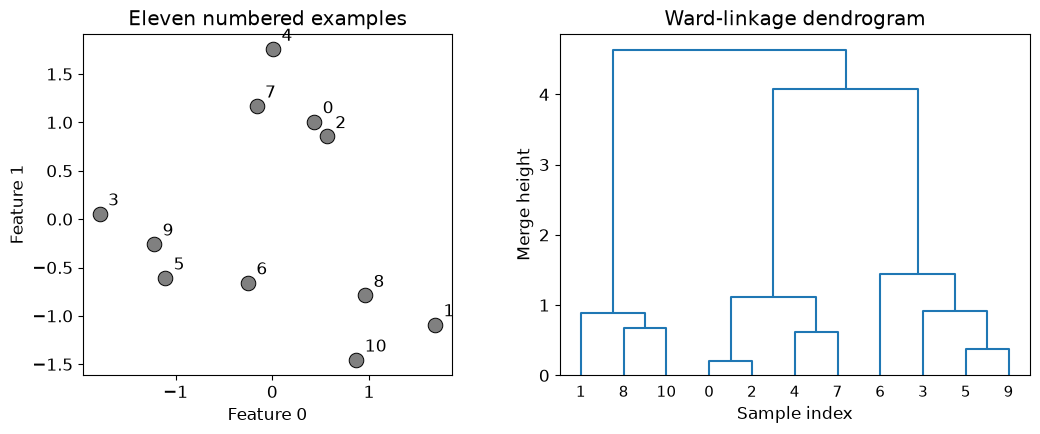

In [10]:
X_hier_original, _ = make_blobs(n_samples=11, centers=3, random_state=0)
X_hier = StandardScaler().fit_transform(X_hier_original)
Z = linkage(X_hier, method="ward", metric="euclidean")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X_hier[:, 0], X_hier[:, 1], s=110, color="grey", edgecolor="black", linewidth=0.7)
for i, point in enumerate(X_hier):
    axes[0].annotate(str(i), point, xytext=(6, 6), textcoords="offset points")
axes[0].set(xlabel="Feature 0", ylabel="Feature 1", title="Eleven numbered examples")
axes[0].set_aspect("equal", adjustable="box")
dendrogram(Z, ax=axes[1], leaf_font_size=11, color_threshold=0)
axes[1].set(xlabel="Sample index", ylabel="Merge height", title="Ward-linkage dendrogram")
plt.tight_layout()

Read the dendrogram from the leaves upward:

- Each leaf represents one example, identified by its original row number.
- Each U-shaped connection records a merge of two points or groups.
- The connection's height indicates how dissimilar the groups were under the chosen distance and linkage rule.

Here, points 0 and 2 merge first, then points 5 and 9, followed by points 4 and 7. Find these pairs in the scatter plot. Each merge reduces the number of clusters by one.

Groups that merge low in the tree are more similar under the chosen rule. Large vertical gaps suggest possible levels at which to cut. The **horizontal distance between leaves does not measure similarity**: branches can rotate without changing the hierarchy. For Ward linkage, used here, merge height is related to the increase in within-cluster squared deviation; it is not simply a distance between two individual points.

### Cutting the hierarchy

A dendrogram contains many possible flat clusterings. Imagine drawing a horizontal line across the tree. Every connected component below that line becomes one cluster. We can choose a cut by requesting a maximum number of clusters or by setting a distance threshold.


In [11]:
# Request at most three clusters from the already fitted hierarchy.
labels_three = fcluster(Z, t=3, criterion="maxclust")
pd.DataFrame({"sample": np.arange(len(X_hier)), "cluster": labels_three})

,sample,cluster
0,0,2
1,1,1
2,2,2
3,3,3
4,4,2
5,5,3
6,6,3
7,7,2
8,8,1
9,9,3


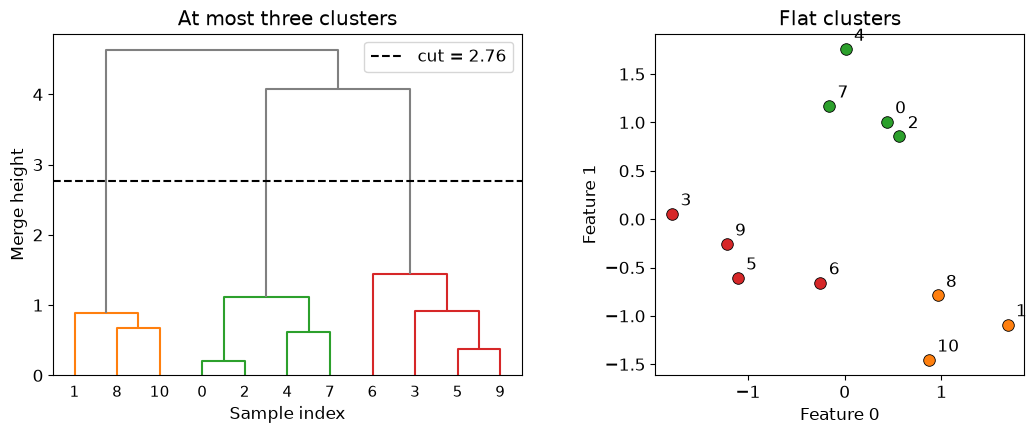

In [12]:
# For this tree, a cut between the last two relevant merge heights gives three groups.
cut_three = (Z[-3, 2] + Z[-2, 2]) / 2
plot_hierarchy_cut(X_hier, Z, labels_three, cut_three, "At most three clusters")

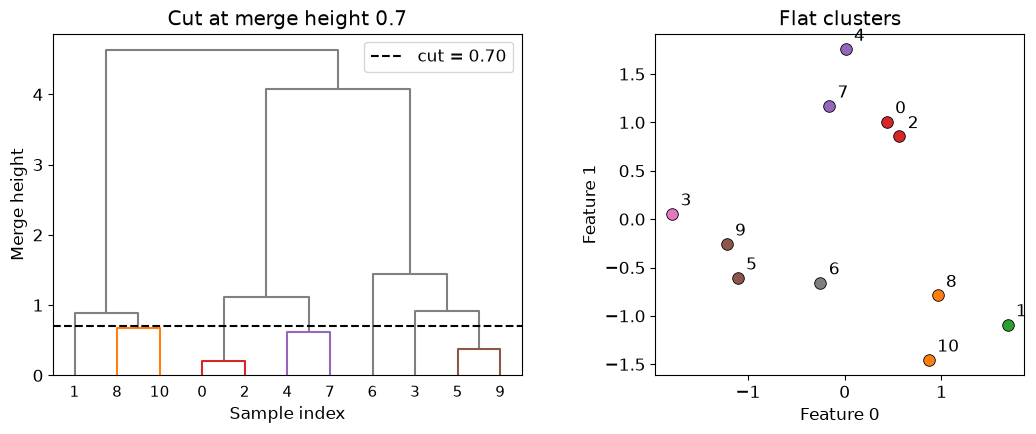

In [13]:
# Alternatively, specify a merge-height threshold directly.
cut_height = 0.7
labels_distance = fcluster(Z, t=cut_height, criterion="distance")
plot_hierarchy_cut(X_hier, Z, labels_distance, cut_height, "Cut at merge height 0.7")

Both calls reuse the same `Z`; they do not rebuild the hierarchy. `criterion="maxclust"` requests **at most** the specified number of clusters, while `criterion="distance"` specifies a merge-height threshold. The threshold's meaning depends on the linkage rule.

Labels are returned in original row order, even though the dendrogram rearranges leaves for display. SciPy's `fcluster` labels start at 1 and are simply group identifiers. The colours above match the flat labels, and the dashed line shows the cut. Changing dendrogram colours alone does not extract labels. See the [SciPy `fcluster` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.fcluster.html) for the two criteria.

### Linkage criteria and distance metric

What does “merge the closest clusters” mean once a cluster contains several points? We need two choices:

- A **distance metric** measures dissimilarity between individual examples.
- A **linkage criterion** determines how to compare whole clusters.

| Linkage | Which two clusters merge next? | Typical behaviour |
|---|---|---|
| Single | Those with the smallest **minimum** cross-cluster distance | Can follow curves, but is vulnerable to chains of points |
| Complete | Those with the smallest **maximum** cross-cluster distance | Favours groups whose members are all reasonably close |
| Average | Those with the smallest **average** cross-cluster distance | Balances the nearest and farthest pairs |
| Ward | Those causing the smallest increase in total within-cluster squared deviation | Favours compact groups and requires Euclidean distance |

First, keep Euclidean distance fixed and compare the linkage rules on the moons.

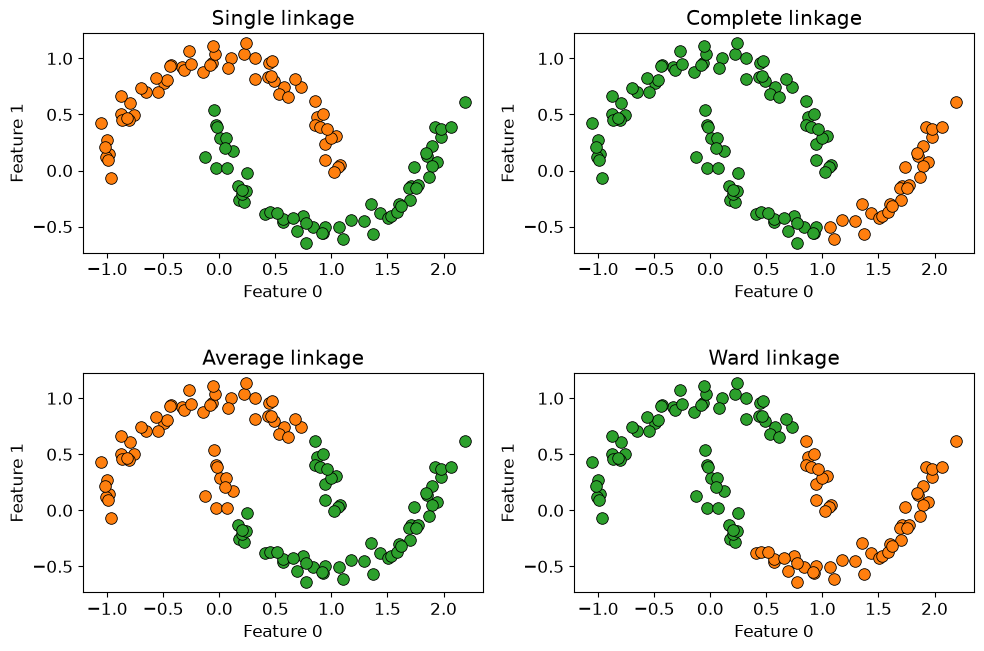

In [14]:
methods = ["single", "complete", "average", "ward"]
X_link, _ = make_moons(n_samples=120, noise=0.07, random_state=7)
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, method in zip(axes.flat, methods):
    Z_method = linkage(X_link, method=method, metric="euclidean")
    labels = fcluster(Z_method, t=2, criterion="maxclust")
    plot_cluster_labels(X_link, labels, ax=ax, title=f"{method.title()} linkage")
plt.tight_layout()

Single linkage can follow the two curved groups because it only needs nearby points to connect them. Complete, average, and Ward linkage prefer more compact groups and may divide this dataset differently. This does not make single linkage universally superior: its chaining behaviour can be undesirable in noisy data.


::: {.callout-reflection}
Suppose clusters A and B have one very close pair of points but also some widely separated pairs. Clusters A and C have no extremely close pair, but all their cross-cluster distances are moderate. Which pair would single linkage favour? Could complete linkage favour a different pair?
:::

Single linkage favours A and B if their nearest pair is the closest across all candidate merges. Complete linkage can instead favour A and C because its decision depends on the farthest pair.

We can specify **both choices** when calling `linkage` with a feature matrix. For example, if `X` contains numerical document features:

```python
Z = linkage(X, method="complete", metric="cosine")
```

Here, `metric="cosine"` compares the directions of two feature vectors rather than their absolute magnitudes. `method="complete"` compares two clusters using the **largest cosine distance** between their members. The two arguments do different jobs; choosing complete linkage does not fix the point-to-point distance metric.

Euclidean distance is the default. Single, complete, and average linkage can use other supported distances, including cosine. **Ward requires Euclidean distance**, so do not combine `method="ward"` with `metric="cosine"`. Choose a metric that makes sense for the representation, and avoid zero vectors when using cosine distance. See the [SciPy `linkage` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html) for supported options.

### Truncating dendrograms

A full dendrogram becomes difficult to read with hundreds or thousands of examples. We can **truncate the display** to show a summary of the hierarchy. In the example below, `truncate_mode="lastp"` with `p=15` shows 15 leaves after collapsing earlier merges. A parenthesized number gives the number of examples in a collapsed group; an unparenthesized number identifies an individual example.

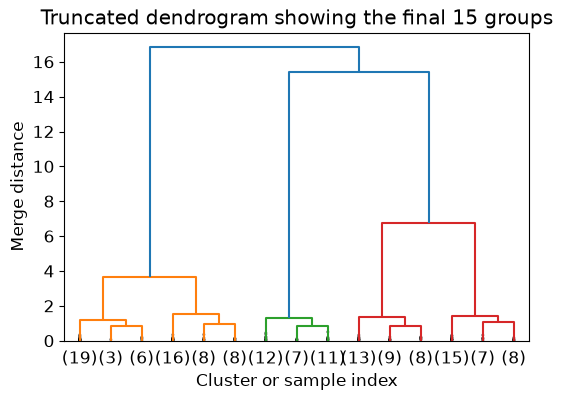

In [15]:
X_large, _ = make_blobs(n_samples=150, centers=5, random_state=4)
Z_large = linkage(StandardScaler().fit_transform(X_large), method="ward")
dendrogram(Z_large, truncate_mode="lastp", p=15, show_contracted=True)
plt.title("Truncated dendrogram showing the final 15 groups")
plt.xlabel("Cluster or sample index")
plt.ylabel("Merge distance");


Another option is `truncate_mode="level"`, where `p` limits the displayed depth from the final merge. Truncation changes only the **display**: all observations still contribute to the fitted hierarchy, and `fcluster` can still return a label for every example.

Truncating the plot does not reduce the cost of fitting. Standard agglomerative methods often require roughly quadratic memory, which can make them impractical for very large datasets.

::: {.callout-note collapse="true" title="Optional: How the hierarchy is stored"}

SciPy's `linkage` function stores the hierarchy in an $(n-1) 	imes 4$ matrix. Each row records one merge:

1. the index of the first cluster,
2. the index of the second cluster,
3. their dissimilarity when merged, and
4. the number of original examples in the new cluster.

Indices below $n$ refer to original examples. Indices starting at $n$ refer to clusters created by earlier rows.

In [16]:
linkage_table = pd.DataFrame(
    Z,
    columns=["cluster 1", "cluster 2", "merge distance", "cluster size"],
)
linkage_table.head().round(3)


,cluster 1,cluster 2,merge distance,cluster size
0,0.0,2.0,0.201,2.0
1,5.0,9.0,0.369,2.0
2,4.0,7.0,0.611,2.0
3,8.0,10.0,0.674,2.0
4,1.0,14.0,0.889,3.0


:::

### Exercise 2: Linkage and dendrograms

1. A dendrogram has a large vertical gap between the merge that creates four clusters and the next merge, which creates three. What does this suggest? Does it prove that four is the correct number?
2. If a thin chain of points connects two dense groups, which linkage criterion is most likely to join them early?
3. A student writes `linkage(X, method="complete", metric="cosine")`. Explain the role of each argument. Could they replace complete linkage with Ward while keeping cosine distance?
4. If you change only the dendrogram's colouring threshold, have you obtained an array of flat cluster labels? What function would you use?

::: {.callout-tip collapse="true" title="Solution"}

1. Four groups are a plausible cut because the next merge combines relatively dissimilar groups. This is evidence under the chosen representation, metric, and linkage, not proof of a correct number.
2. Single linkage, because successive nearby pairs can connect the groups.
3. Cosine measures dissimilarity between individual rows. Complete linkage uses the maximum cross-cluster cosine distance to compare groups. Ward requires Euclidean distance, so that replacement is not valid.
4. No. Colouring affects the display. Use `fcluster` to extract labels, choosing a maximum cluster count or a merge-height threshold.
:::

## Choosing a clustering method

No method is best for every dataset. The right choice depends on what a cluster should mean in the application.

| Consideration | K-Means | DBSCAN | Agglomerative hierarchical |
|---|---|---|---|
| Main idea | Nearest centre | Connected dense region | Repeatedly merge similar clusters |
| Main choices | Number of clusters | `eps`, `min_samples` | Linkage and where to cut |
| Typical cluster shapes | Compact and roughly spherical | Irregular, density-connected shapes | Depends strongly on linkage |
| Noise points | Every point is assigned | Can leave points as noise | Standard flat cuts assign every point |
| New examples | `predict` is available | No standard `predict` | No standard `predict` |
| Scalability | Usually the strongest of the three | Can scale well with an efficient neighbour search | Often limited by quadratic memory |
| Particularly useful when | Groups have representative centres | Noise and non-spherical groups matter | Nested structure or several resolutions matter |

These descriptions are tendencies rather than guarantees. For example, DBSCAN's success on irregular shapes depends on the clusters having compatible densities.


## Evaluating and interpreting clusters

Recall the **silhouette score** from K-Means: it compares how close each example is to its own cluster with how close it is to the nearest alternative cluster. We can also use it for DBSCAN and hierarchical clustering. However, it can undervalue irregular shapes, and DBSCAN noise needs explicit treatment. For example, we might calculate the score on non-noise points, provided at least two clusters remain and there are more points than clusters, and report the noise fraction alongside it. Otherwise, a score may hide how much data was excluded.

A numerical score is only supporting evidence. For exploratory clustering, the main question is: **can we tell a useful, evidence-based story about the structure of the data?** If people cannot interpret the groups or connect them to the task, a clean partition has limited value.

For document clusters, read several documents from each group, including typical examples and exceptions. What theme do they share? How does it differ from other groups? Does a proposed description fit most members, or only a few convenient examples? Inspect noise documents too: they might contain unusual topics, mixed content, or problems with the representation.

A plausible story is not enough on its own. Check whether the interpretation survives reasonable changes to parameters or preprocessing. A useful report might say, “This group mostly contains discussions of public transport, with a few broader city-planning documents; it persists across nearby settings.” That is more informative than reporting only a silhouette score or cluster count.

If trustworthy external labels are available, the adjusted Rand index can compare partitions without assuming that their numeric IDs match. Ordinary label accuracy is unsuitable because cluster IDs are arbitrary:

In [17]:
# Cluster IDs can be permuted without changing the partition.
y_a = np.array([0, 0, 1, 1, 2, 2])
y_b = np.array([2, 2, 0, 0, 1, 1])

print("Fraction of identical numeric labels:", np.mean(y_a == y_b))
print("Adjusted Rand index:", adjusted_rand_score(y_a, y_b))


Fraction of identical numeric labels: 0.0
Adjusted Rand index: 1.0


Use numerical evidence, stability checks, and manual interpretation together. Stable clusters can still reflect an irrelevant distinction, such as document length rather than topic. Return to the purpose of the analysis when deciding whether the structure is useful.

::: {.callout-important}
## Representation defines similarity

All three methods rely on distances, directly or indirectly. Feature selection, transformations, scaling, and the distance metric determine which examples appear similar. A clustering algorithm can faithfully reveal structure in its input representation while completely missing the semantic structure relevant to the application.
:::


### Exercise 3: Choosing a method

Choose a reasonable starting method for each situation and explain your choice. More than one answer may be defensible.

1. Millions of observations appear to form a few compact groups, and every new observation must be assigned immediately.
2. A spatial dataset contains winding regions together with isolated measurement errors.
3. A biologist wants to explore nested similarities among 40 species before choosing a level of detail.
4. A dataset appears to contain groups with very different densities.


::: {.callout-tip collapse="true" title="Solution"}

1. K-Means is a natural starting point because it scales well and provides `predict` for new examples.
2. DBSCAN is a natural starting point because it can follow irregular density-connected shapes and label isolated observations as noise.
3. Hierarchical clustering and a dendrogram directly represent nested groupings at several resolutions.
4. None of these methods is guaranteed to work well. Standard DBSCAN is especially vulnerable to varying density; careful representation, parameter exploration, and possibly a method designed for varying density would be appropriate. Domain inspection remains essential.
:::


## Summary

- **DBSCAN groups points through density connections.** Core points extend clusters, border points join without extending them, and noise points remain unassigned with label `-1`.
- **Tune `eps` and `min_samples` together.** Try a small range of settings, inspect cluster sizes and noise fractions, and examine representative examples. Suitable values depend on the representation and distance metric.
- **DBSCAN has limitations.** Varying densities and dense bridges can prevent it from finding the groups we want. It has no standard `predict` method for new observations.
- **Hierarchical clustering lets us explore several levels of grouping.** Read the merge sequence in a dendrogram, then use `fcluster` to obtain flat labels. Truncation simplifies the display without changing the fitted hierarchy.
- **Distance metric and linkage criterion are separate choices.** The metric compares individual examples; linkage compares groups. Ward requires Euclidean distance.
- **Useful clusters need interpretation.** Silhouette scores and stability checks provide evidence, but representative examples and domain knowledge should support a meaningful account of the data's structure.

## Resources

- [Clustering methods in the scikit-learn user guide](https://scikit-learn.org/stable/modules/clustering.html)
- [DBSCAN API documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- [SciPy hierarchical clustering documentation](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html)
- [Interactive DBSCAN visualization](https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/)
